In [96]:
import numpy as np 
import pandas as pd
from pathlib import Path 
import matplotlib.pyplot as plt 
import seaborn as sns 
%matplotlib inline 

In [97]:
# %pip install scikit-learnw    

In [98]:
data_path = Path("../data/raw/loan_approval_dataset.csv")

print("Dataset exists:",data_path.exists())


Dataset exists: True


In [99]:
df = pd.read_csv(data_path)

## Exploratory Data Analysis

In [100]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [101]:
print("Shape:", df.shape)

Shape: (4269, 13)


In [102]:
df.columns.to_list()

['loan_id',
 ' no_of_dependents',
 ' education',
 ' self_employed',
 ' income_annum',
 ' loan_amount',
 ' loan_term',
 ' cibil_score',
 ' residential_assets_value',
 ' commercial_assets_value',
 ' luxury_assets_value',
 ' bank_asset_value',
 ' loan_status']

In [103]:
df.columns= df.columns.str.strip()

In [104]:
df.columns.to_list()

['loan_id',
 'no_of_dependents',
 'education',
 'self_employed',
 'income_annum',
 'loan_amount',
 'loan_term',
 'cibil_score',
 'residential_assets_value',
 'commercial_assets_value',
 'luxury_assets_value',
 'bank_asset_value',
 'loan_status']

In [105]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [106]:
df.describe(include="all")

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
count,4269.000000,4269.000000,4269,4269,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03,4269
unique,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,NaN,NaN,Graduate,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Approved
freq,NaN,NaN,2144,2150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2656
mean,2135.000000,2.498712,NaN,NaN,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06,NaN
std,1232.498479,1.695910,NaN,NaN,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06,NaN
min,1.000000,0.000000,NaN,NaN,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00,NaN
25%,1068.000000,1.000000,NaN,NaN,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06,NaN
50%,2135.000000,3.000000,NaN,NaN,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06,NaN
75%,3202.000000,4.000000,NaN,NaN,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06,NaN


In [107]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
    "unique_values": df.nunique(),
})
display(quality)
print("Duplicate rows:", df.duplicated().sum())

,dtype,missing,missing_%,unique_values
loan_id,int64,0,0.0,4269
no_of_dependents,int64,0,0.0,6
education,object,0,0.0,2
self_employed,object,0,0.0,2
income_annum,int64,0,0.0,98
loan_amount,int64,0,0.0,378
loan_term,int64,0,0.0,10
cibil_score,int64,0,0.0,601
residential_assets_value,int64,0,0.0,278
commercial_assets_value,int64,0,0.0,188


Duplicate rows: 0


In [108]:
money_cols = ["income_annum", "loan_amount", "residential_assets_value",
              "commercial_assets_value", "luxury_assets_value", "bank_asset_value"]

print("Negative values per money column:")
print((df[money_cols] < 0).sum())
print()
print("CIBIL outside 300-900:", ((df["cibil_score"] < 300) | (df["cibil_score"] > 900)).sum())
print("Loan terms present (years):", sorted(df["loan_term"].unique()))
print("Rows with loan_amount > 10 x annual income:", (df["loan_amount"] > 10 * df["income_annum"]).sum())

Negative values per money column:
income_annum                 0
loan_amount                  0
residential_assets_value    28
commercial_assets_value      0
luxury_assets_value          0
bank_asset_value             0
dtype: int64

CIBIL outside 300-900: 0
Loan terms present (years): [np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10), np.int64(12), np.int64(14), np.int64(16), np.int64(18), np.int64(20)]
Rows with loan_amount > 10 x annual income: 0


In [109]:
df[money_cols] = df[money_cols].clip(lower=0)
(df[money_cols] < 0).sum().sum()

np.int64(0)

### Target distribution

In [110]:
target_col = "loan_status"

Using target column : loan_status


loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

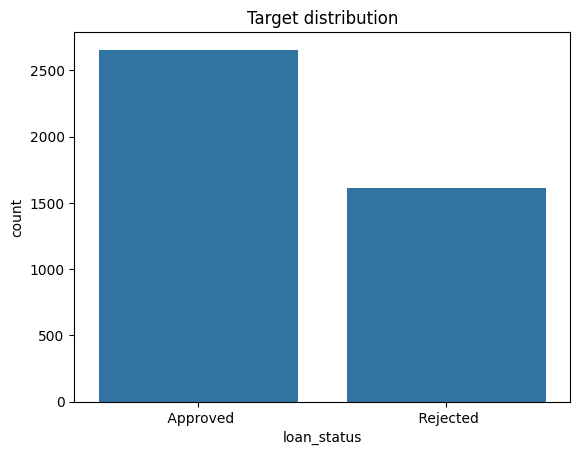

In [111]:
print("Using target column :",target_col)
display(df[target_col].value_counts(dropna=False))
sns.countplot(x=target_col,data=df)
plt.title("Target distribution")
plt.show()

In [112]:
df =df.drop(columns=["loan_id"],errors="ignore")

In [113]:
df.head(1)

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved


In [114]:
df_clf = df.dropna(subset=[target_col]).copy()

In [115]:
X= df_clf.drop(columns=[target_col])
y= df_clf[target_col].copy()

In [116]:
X.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000


In [117]:
y.head()

0     Approved
1     Rejected
2     Rejected
3     Rejected
4     Rejected
Name: loan_status, dtype: object

## feature engineering


In [118]:
cat_cols = X.select_dtypes(include=["object","category"]).columns.to_list()
num_cols = X.select_dtypes(include=[np.number]).columns.to_list()

In [119]:
print("categorical columns:",cat_cols)
print("Numerical columns:",num_cols)

categorical columns: ['education', 'self_employed']
Numerical columns: ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']


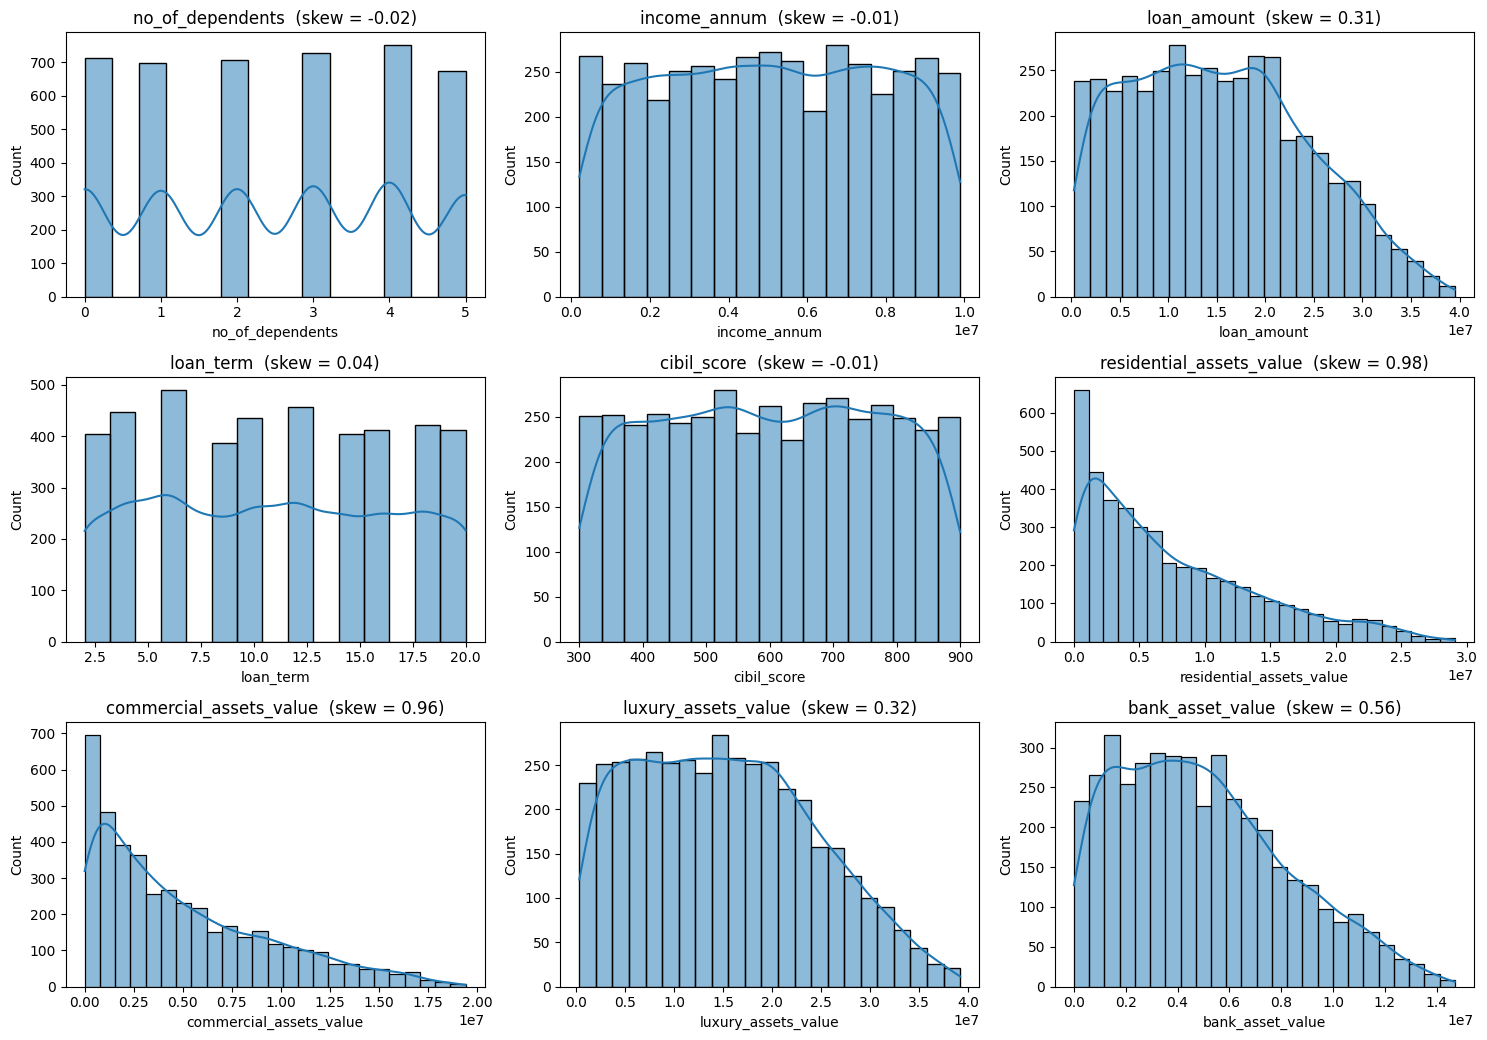

,skew,kurtosis
no_of_dependents,-0.02,-1.26
income_annum,-0.01,-1.18
loan_amount,0.31,-0.74
loan_term,0.04,-1.22
cibil_score,-0.01,-1.19
residential_assets_value,0.98,0.19
commercial_assets_value,0.96,0.10
luxury_assets_value,0.32,-0.74
bank_asset_value,0.56,-0.40


In [120]:
def grid_plot(cols, plot_fn, ncols=3, figsize_per=(5, 3.5)):
    nrows = (len(cols) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per[0] * ncols, figsize_per[1] * nrows))
    axes = np.array(axes).ravel()
    for ax, col in zip(axes, cols):
        plot_fn(col, ax)
    for ax in axes[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

def hist_with_skew(col, ax):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")

grid_plot(num_cols, hist_with_skew)
display(pd.DataFrame({"skew": df[num_cols].skew(), "kurtosis": df[num_cols].kurt()}).round(2))

,outliers_IQR,outlier_%
no_of_dependents,0,0.00
income_annum,0,0.00
loan_amount,0,0.00
loan_term,0,0.00
cibil_score,0,0.00
residential_assets_value,52,1.22
commercial_assets_value,37,0.87
luxury_assets_value,0,0.00
bank_asset_value,5,0.12


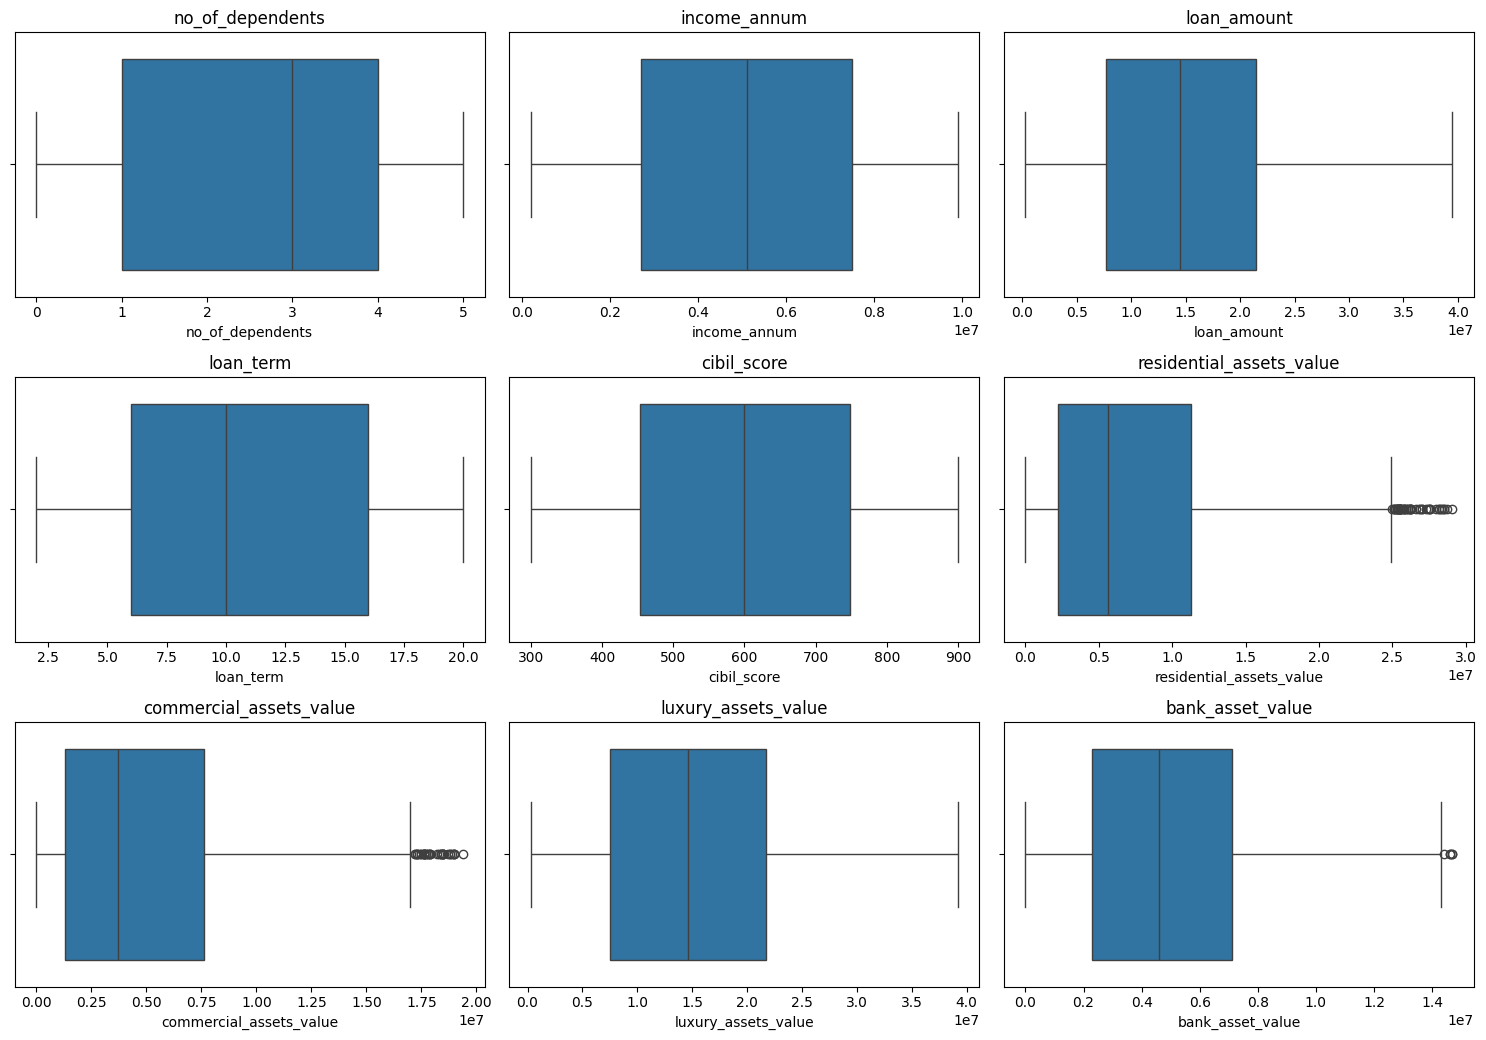

In [121]:
def iqr_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

outlier_table = pd.DataFrame({"outliers_IQR": {c: iqr_outliers(df[c]) for c in num_cols}})
outlier_table["outlier_%"] = (outlier_table["outliers_IQR"] / len(df) * 100).round(2)
display(outlier_table)

grid_plot(num_cols, lambda col, ax: (sns.boxplot(x=df[col], ax=ax), ax.set_title(col)))

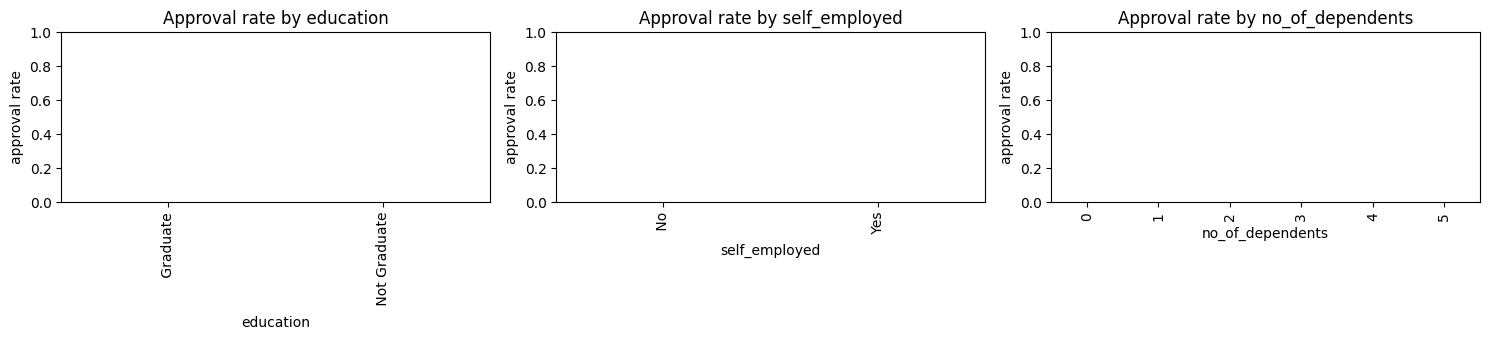

In [122]:
cat_like = cat_cols + ["no_of_dependents"]
approved_flag = (df["loan_status"] == "Approved").astype(int)
def approval_rate_bar(col, ax):
    rate = approved_flag.groupby(df[col]).mean()
    rate.plot(kind="bar", ax=ax)
    ax.set_ylim(0, 1)
    ax.set_title(f"Approval rate by {col}")
    ax.set_ylabel("approval rate")

grid_plot(cat_like, approval_rate_bar)

loan_status,Approved,Rejected
no_of_dependents,2.5,2.5
income_annum,5025903.6,5113825.2
loan_amount,15247251.5,14946063.2
loan_term,10.4,11.7
cibil_score,703.5,429.5
residential_assets_value,7400414.2,7593242.4
commercial_assets_value,5001355.4,4926720.4
luxury_assets_value,15016603.9,15306943.6
bank_asset_value,4959525.6,5004959.7


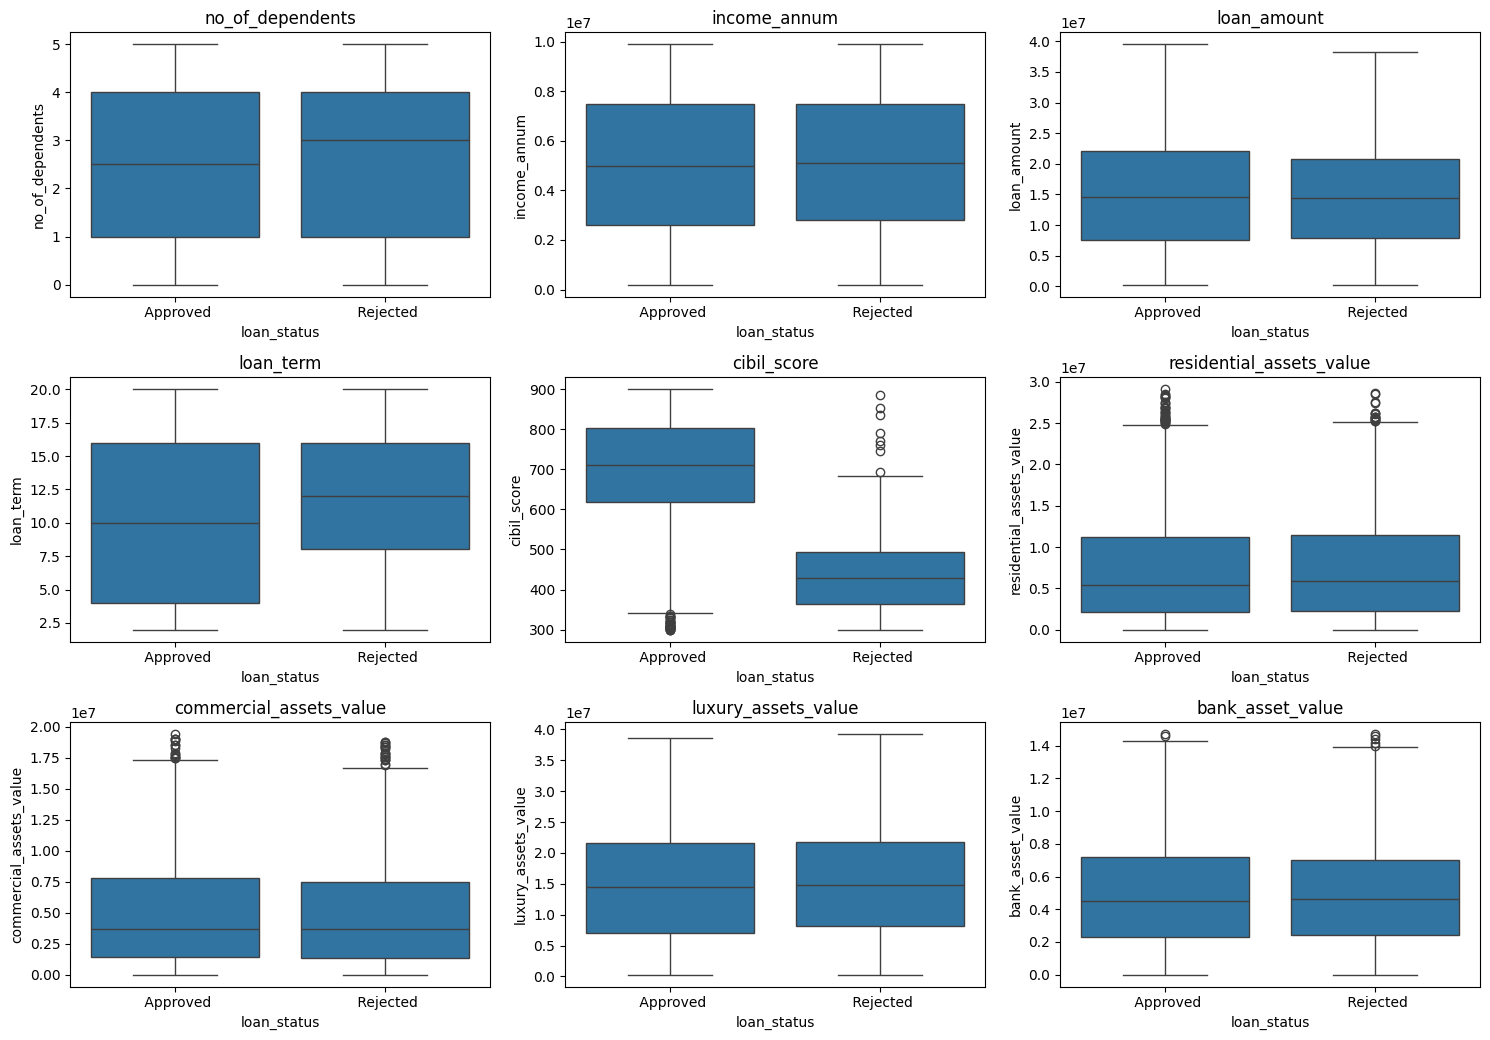

In [123]:
display(df.groupby("loan_status")[num_cols].mean().T.round(1))

grid_plot(num_cols, lambda col, ax: (sns.boxplot(x="loan_status", y=col, data=df, ax=ax), ax.set_title(col)))


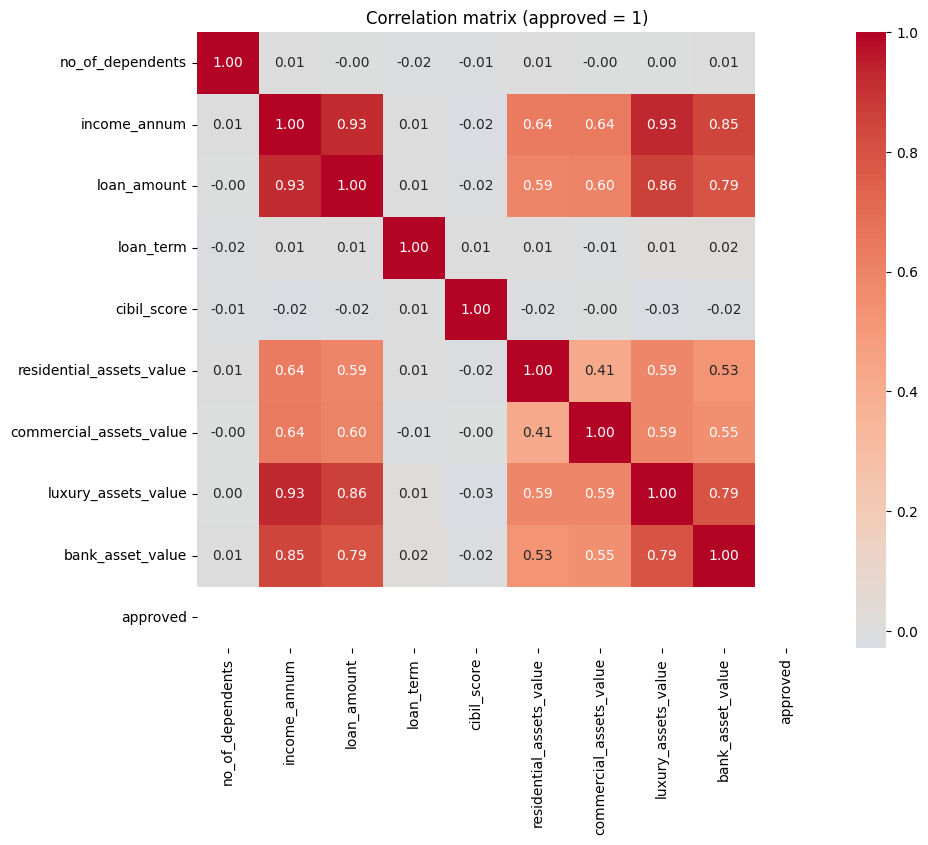

Correlation with approval:
no_of_dependents           NaN
income_annum               NaN
loan_amount                NaN
loan_term                  NaN
cibil_score                NaN
residential_assets_value   NaN
commercial_assets_value    NaN
luxury_assets_value        NaN
bank_asset_value           NaN
Name: approved, dtype: float64


In [124]:
corr_df = df[num_cols].copy()
corr_df["approved"] = approved_flag

plt.figure(figsize=(10, 8))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (approved = 1)")
plt.show()

print("Correlation with approval:")
print(corr_df.corr()["approved"].drop("approved").sort_values(ascending=False).round(3))

## Preprocesing pipeline 

In [125]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder ,StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline , make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, make_scorer, ConfusionMatrixDisplay, RocCurveDisplay,
                             classification_report)

In [126]:
numerical_pipeline = Pipeline(steps=[
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

In [127]:
categorical_pipeline = Pipeline(steps=
    [("imputer",SimpleImputer(strategy="most_frequent")),
     ("onehot",OneHotEncoder(handle_unknown="ignore"))
      ])

In [128]:
preprocessor = ColumnTransformer(transformers=[
    ("num",numerical_pipeline,num_cols),
    ("cat",categorical_pipeline,cat_cols)],
    remainder="drop"
)

In [129]:
preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


# Stage -1 Classification 

In [130]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [131]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

In [132]:
X.head()


,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000


In [133]:
y.head()

0     Approved
1     Rejected
2     Rejected
3     Rejected
4     Rejected
Name: loan_status, dtype: object

In [134]:
unique_vals = sorted(y.unique())
unique_vals

[' Approved', ' Rejected']

In [135]:
y = df_clf[target_col].astype(str).str.strip().str.lower()

In [136]:
unique_vals = sorted(y.unique())
unique_vals

['approved', 'rejected']

In [137]:
y = (y=="approved").astype(int)

In [138]:
unique_vals = sorted(y.unique())
unique_vals

[np.int64(0), np.int64(1)]

In [139]:
y.head()

0    1
1    0
2    0
3    0
4    0
Name: loan_status, dtype: int64

In [140]:
X_train , X_test , y_train, y_test=train_test_split(X,y,test_size=0.20,random_state=10,stratify=y)

In [141]:
print("train size:",X_train.shape)
print("test size:",X_test.shape)

train size: (3415, 11)
test size: (854, 11)


## Fit RF baseline Pipelines

In [47]:
RANDOM_STATE = 42
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "GradientBoosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "precision_approved": "precision",
    "recall_approved": "recall",
    "recall_rejected": make_scorer(recall_score, pos_label=0),
    "f1": "f1",
    "roc_auc": "roc_auc",
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", model)])
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=-1)
    row = {"model": name}
    for k in scoring:
        row[k] = res[f"test_{k}"].mean()
    row["train_f1"] = res["train_f1"].mean()
    row["overfit_gap_f1"] = row["train_f1"] - row["f1"]
    rows.append(row)

cv_table = pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False).round(4)
cv_table

,accuracy,precision_approved,recall_approved,recall_rejected,f1,roc_auc,train_f1,overfit_gap_f1
model,,,,,,,,
GradientBoosting,0.9816,0.9827,0.9878,0.9713,0.9852,0.9981,0.9979,0.0127
RandomForest,0.9795,0.9808,0.9864,0.9682,0.9836,0.9970,1.0000,0.0164
DecisionTree,0.9754,0.9803,0.9802,0.9674,0.9802,0.9738,1.0000,0.0198
LogisticRegression,0.9163,0.9335,0.9318,0.8907,0.9326,0.9691,0.9354,0.0028


In [142]:
param_grids = {
    "LogisticRegression": {"model__C": [0.01, 0.1, 1, 10]},
    "DecisionTree": {"model__max_depth": [3, 5, 8, None], "model__min_samples_leaf": [1, 5, 20]},
    "RandomForest": {"model__n_estimators": [200, 400], "model__max_depth": [None, 6, 10],
                     "model__min_samples_leaf": [1, 3]},
    "GradientBoosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1],
                         "model__max_depth": [2, 3]},
    "XGBoost": {"model__n_estimators": [100, 300], "model__learning_rate": [0.05, 0.1],
                "model__max_depth": [2, 4]}
}

tuned = {}
for name, model in models.items():
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", model)])
    gs = GridSearchCV(pipe, param_grids[name], cv=cv, scoring="roc_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print(f"{name:20s} CV ROC-AUC = {gs.best_score_:.4f}   best = {gs.best_params_}")

LogisticRegression   CV ROC-AUC = 0.9691   best = {'model__C': 1}
DecisionTree         CV ROC-AUC = 0.9957   best = {'model__max_depth': 3, 'model__min_samples_leaf': 5}
RandomForest         CV ROC-AUC = 0.9977   best = {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 400}
GradientBoosting     CV ROC-AUC = 0.9981   best = {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}


In [143]:
def business_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_approved": precision_score(y_true, y_pred),   # of those we approve, how many deserve it
        "recall_approved": recall_score(y_true, y_pred),          # of good applicants, how many we approve
        "recall_rejected": tn / (tn + fp),                        # of bad applicants, how many we catch
        "f1_approved": f1_score(y_true, y_pred),
        "false_approvals": int(fp),                               # costly for the lender
        "false_rejections": int(fn),                              # costly for the customer
    }

In [144]:
rows, test_proba = [], {}
for name, gs in tuned.items():
    proba = gs.best_estimator_.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    row = business_metrics(y_test, pred)
    row["roc_auc"] = roc_auc_score(y_test, proba)
    row["cv_roc_auc"] = gs.best_score_
    rows.append(pd.Series(row, name=name))
    test_proba[name] = proba

test_table = pd.DataFrame(rows).round(4)
test_table

,accuracy,precision_approved,recall_approved,recall_rejected,f1_approved,false_approvals,false_rejections,roc_auc,cv_roc_auc
LogisticRegression,0.9145,0.9272,0.9360,0.8793,0.9316,39.0,34.0,0.9641,0.9691
DecisionTree,0.9614,0.9940,0.9435,0.9907,0.9681,3.0,30.0,0.9961,0.9957
RandomForest,0.9778,0.9848,0.9793,0.9752,0.9821,8.0,11.0,0.9979,0.9977
GradientBoosting,0.9824,0.9850,0.9868,0.9752,0.9859,8.0,7.0,0.9984,0.9981


In [145]:
final_name = max(tuned, key=lambda n: tuned[n].best_score_)
final_clf = tuned[final_name].best_estimator_
print("Final classifier:", final_name)
print("Best params     :", tuned[final_name].best_params_)

COST_FALSE_APPROVAL = 5
COST_FALSE_REJECTION = 1

oof_proba = cross_val_predict(clone(final_clf), X_train, y_train, cv=cv, method="predict_proba")[:, 1]

rows = []
for t in np.arange(0.30, 0.91, 0.05):
    pred = (oof_proba >= t).astype(int)
    fp = int(((pred == 1) & (y_train.values == 0)).sum())
    fn = int(((pred == 0) & (y_train.values == 1)).sum())
    rows.append({"threshold": round(t, 2),
                 "precision_approved": precision_score(y_train, pred),
                 "recall_approved": recall_score(y_train, pred),
                 "false_approvals": fp, "false_rejections": fn,
                 "total_cost": COST_FALSE_APPROVAL * fp + COST_FALSE_REJECTION * fn})
thr_table = pd.DataFrame(rows).set_index("threshold").round(4)
display(thr_table)

best_threshold = float(thr_table["total_cost"].idxmin())
print("Chosen threshold:", best_threshold)

Final classifier: GradientBoosting
Best params     : {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}


,precision_approved,recall_approved,false_approvals,false_rejections,total_cost
threshold,,,,,
0.30,0.9628,0.9976,82,5,415
0.35,0.9676,0.9972,71,6,361
0.40,0.9706,0.9939,64,13,333
0.45,0.9768,0.9901,50,21,271
0.50,0.9822,0.9882,38,25,215
0.55,0.9867,0.9812,28,40,180
0.60,0.9895,0.9755,22,52,162
0.65,0.9904,0.9708,20,62,162
0.70,0.9918,0.9647,17,75,160


Chosen threshold: 0.75


Final model: GradientBoosting   threshold = 0.75
accuracy               0.9672
precision_approved     0.9941
recall_approved        0.9529
recall_rejected        0.9907
f1_approved            0.9731
false_approvals        3.0000
false_rejections      25.0000
dtype: float64

              precision    recall  f1-score   support

    Rejected       0.93      0.99      0.96       323
    Approved       0.99      0.95      0.97       531

    accuracy                           0.97       854
   macro avg       0.96      0.97      0.97       854
weighted avg       0.97      0.97      0.97       854



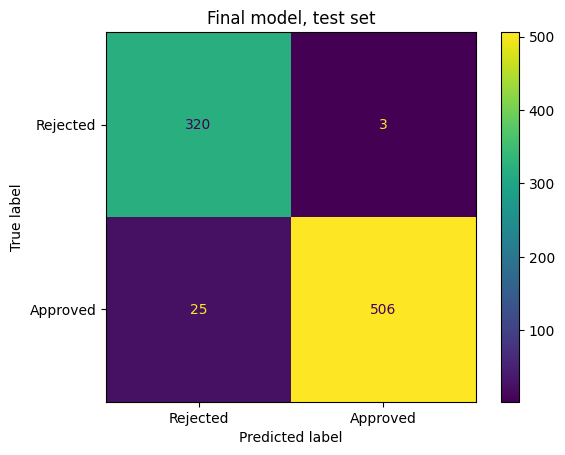

In [146]:
final_proba = final_clf.predict_proba(X_test)[:, 1]
final_pred = (final_proba >= best_threshold).astype(int)

print(f"Final model: {final_name}   threshold = {best_threshold}")
print(pd.Series(business_metrics(y_test, final_pred)).round(4))
print()
print(classification_report(y_test, final_pred, target_names=["Rejected", "Approved"]))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=["Rejected", "Approved"])
plt.title("Final model, test set")
plt.show()

cibil_score                 0.4893
loan_term                   0.0252
loan_amount                 0.0073
residential_assets_value    0.0049
income_annum                0.0033
luxury_assets_value         0.0010
commercial_assets_value     0.0004
bank_asset_value            0.0003
no_of_dependents            0.0000
self_employed               0.0000
dtype: float64

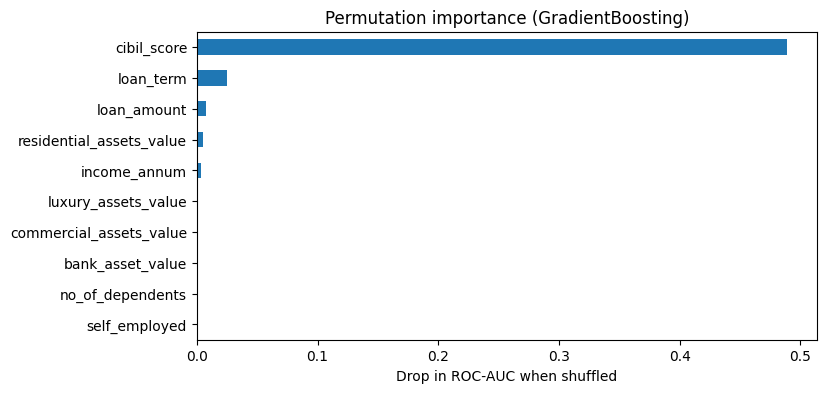

In [147]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(final_clf, X_test, y_test, scoring="roc_auc",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_clf = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
display(perm_clf.round(4).head(10))

perm_clf.head(10).iloc[::-1].plot(kind="barh", figsize=(8, 4))
plt.xlabel("Drop in ROC-AUC when shuffled")
plt.title(f"Permutation importance ({final_name})")
plt.show()

In [148]:
rf_clf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('rf_cls', RandomForestClassifier())
])

In [49]:
from sklearn.model_selection import GridSearchCV

In [50]:
param_grid = {
    'rf_cls__n_estimators' : [100,200,300,400],
    'rf_cls__max_depth' : [None, 4, 8, 10],
    'rf_cls__max_features' : ['sqrt', None]
}

grid = GridSearchCV(rf_clf_pipeline, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)
print("Best params (rf_cls) : ", grid.best_params_)
print("="*80)
best_clf = grid.best_estimator_
y_pred_best = best_clf.predict(X_test)
print(classification_report(y_test, y_pred_best))

Best params (rf_cls) :  {'rf_cls__max_depth': None, 'rf_cls__max_features': None, 'rf_cls__n_estimators': 400}
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       323
           1       0.99      0.99      0.99       531

    accuracy                           0.99       854
   macro avg       0.98      0.99      0.99       854
weighted avg       0.99      0.99      0.99       854



In [149]:

# Random forest final baseline model
rf_clf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('rf_cls', RandomForestClassifier(n_estimators=400, max_depth=None, max_features=None,random_state=10, oob_score=True))
])

rf_clf_pipeline.fit(X_train, y_train)
y_pred_cls = rf_clf_pipeline.predict(X_test)
print(classification_report(y_test, y_pred_cls))
print("RF cls OOB score :", getattr(rf_clf_pipeline.named_steps['rf_cls'], 'oob_score_', None))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       323
           1       0.99      0.99      0.99       531

    accuracy                           0.99       854
   macro avg       0.98      0.99      0.99       854
weighted avg       0.99      0.99      0.99       854

RF cls OOB score : 0.9844802342606149


In [52]:
rf_clf_pipeline

,steps,"[('preprocessor', ...), ('rf_cls', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Top 10 Important Features : 
                           Feature  Importance
4                num__cibil_score    0.827636
3                  num__loan_term    0.079926
2                num__loan_amount    0.035943
1               num__income_annum    0.021856
7        num__luxury_assets_value    0.008155
6    num__commercial_assets_value    0.007139
5   num__residential_assets_value    0.007032
8           num__bank_asset_value    0.005642
0           num__no_of_dependents    0.004293
11         cat__self_employed_ No    0.000850


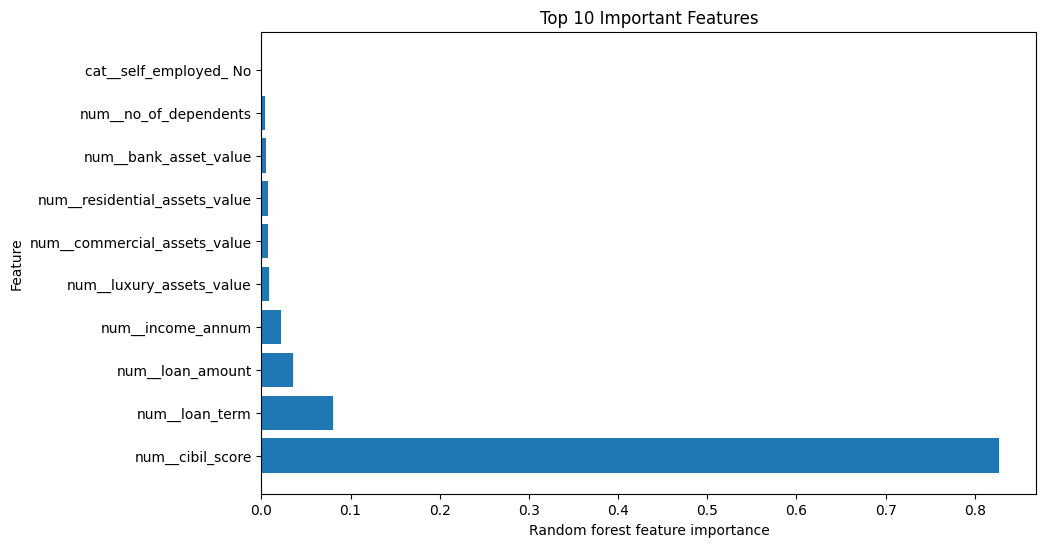

In [53]:
feature_importance = rf_clf_pipeline.named_steps['rf_cls'].feature_importances_

preprocessor = rf_clf_pipeline.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame(
    {
        'Feature' : feature_names,
        'Importance'  : feature_importance
    }
)

importance_df = importance_df.sort_values(by='Importance', ascending=False)

print("Top 10 Important Features : \n", importance_df.head(10))

plt.figure(figsize=(10,6))
plt.barh(importance_df['Feature'][:10], importance_df['Importance'][:10])
plt.xlabel("Random forest feature importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features")
plt.show()


# Stage 2 : regression

In [151]:
df["loan_status"].unique()

array([' Approved', ' Rejected'], dtype=object)

In [152]:
df["loan_status"] = df["loan_status"].str.strip()

In [153]:
df["loan_status"].unique()

array(['Approved', 'Rejected'], dtype=object)

In [154]:
approved_df = df[df["loan_status"] == "Approved"].copy()

In [155]:

approved_df.shape

(2656, 12)

In [156]:
approved_df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
6,5,Graduate,No,8700000,33000000,4,678,22500000,14800000,29200000,4300000,Approved
8,0,Graduate,Yes,800000,2200000,20,782,1300000,800000,2800000,600000,Approved
10,4,Graduate,Yes,2900000,11200000,2,547,8100000,4700000,9500000,3100000,Approved
13,2,Graduate,Yes,9100000,31500000,14,679,10800000,16600000,20900000,5000000,Approved


In [157]:
reg_target = "loan_amount"
reg_df = approved_df.dropna(subset=[reg_target]).copy()

In [158]:
X_reg = reg_df.drop(columns=[reg_target])
y_reg = reg_df[reg_target]

In [159]:
cat_cols_reg = X_reg.select_dtypes(include=['object', 'category']).columns.to_list()
num_cols_reg = X_reg.select_dtypes(include=[np.number]).columns.to_list()

In [160]:
print("Categorical columns : ", cat_cols_reg)
print("Numerical columns : ", num_cols_reg)

Categorical columns :  ['education', 'self_employed', 'loan_status']
Numerical columns :  ['no_of_dependents', 'income_annum', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']


In [161]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=10)
print("Train size : ", Xr_train.shape)
print("Test size : ", Xr_test.shape)


Train size :  (2124, 11)
Test size :  (532, 11)


In [162]:

reg_preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_pipeline, num_cols_reg),
    ('cat', categorical_pipeline, cat_cols_reg)
], remainder='drop')

# Fit RF_reg baseline model

In [166]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

In [168]:
reg_models = {
    "LinearRegression": LinearRegression(),
    "DecisionTree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    "GradientBoosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(random_state=RANDOM_STATE)
}

from sklearn.model_selection import KFold
reg_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

rows = []
for name, model in reg_models.items():
    pipe = Pipeline([("prep", clone(reg_preprocessor)), ("model", model)])
    res = cross_validate(pipe, Xr_train, yr_train, cv=reg_cv, scoring=reg_scoring, n_jobs=-1)
    rows.append({"model": name,
                 "r2": res["test_r2"].mean(),
                 "mae": -res["test_mae"].mean(),
                 "rmse": -res["test_rmse"].mean()})
reg_cv_table = pd.DataFrame(rows).set_index("model").sort_values("mae")
reg_cv_table.round(3)

,r2,mae,rmse
model,,,
GradientBoosting,0.871,2488501.726,3321724.287
RandomForest,0.865,2519973.862,3389796.310
LinearRegression,0.870,2534336.124,3335246.570
XGBoost,0.844,2668586.450,3641615.500
DecisionTree,0.749,3252929.523,4625944.158


In [169]:
reg_models = {
    "LinearRegression": LinearRegression(),
    "DecisionTree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    "GradientBoosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(random_state=RANDOM_STATE)
}

from sklearn.model_selection import KFold
reg_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
reg_scoring = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

rows = []
for name, model in reg_models.items():
    pipe = Pipeline([("prep", clone(reg_preprocessor)), ("model", model)])
    res = cross_validate(pipe, Xr_train, yr_train, cv=reg_cv, scoring=reg_scoring, n_jobs=-1)
    rows.append({"model": name,
                 "r2": res["test_r2"].mean(),
                 "mae": -res["test_mae"].mean(),
                 "rmse": -res["test_rmse"].mean()})
reg_cv_table = pd.DataFrame(rows).set_index("model").sort_values("mae")
reg_cv_table.round(3)

,r2,mae,rmse
model,,,
GradientBoosting,0.871,2488501.726,3321724.287
RandomForest,0.865,2519973.862,3389796.310
LinearRegression,0.870,2534336.124,3335246.570
XGBoost,0.844,2668586.450,3641615.500
DecisionTree,0.749,3252929.523,4625944.158


In [174]:
reg_grids = {
    "LinearRegression": {},
    "DecisionTree": {"max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 5, 20]},
    "RandomForest": {"n_estimators": [200, 400], "max_depth": [6, 8, None], "min_samples_leaf": [1, 5]},
    "GradientBoosting": {"n_estimators": [100, 300], "learning_rate": [0.05, 0.1], "max_depth": [2, 3]},
    "XGBoost": {"n_estimators": [100, 300], "learning_rate": [0.05, 0.1], "max_depth": [2, 4]},
}

reg_tuned = {}
prefix = "model__"
for name, model in reg_models.items():
    pipe = Pipeline([("prep", clone(reg_preprocessor)), ("model", model)])
    grid = {prefix+k: v for k, v in reg_grids[name].items()}
    gs = GridSearchCV(pipe, grid, cv=reg_cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    gs.fit(Xr_train, yr_train)
    reg_tuned[name] = gs
    print(f"{name:18s} CV MAE = {-gs.best_score_:,.0f}   best = {gs.best_params_}")

LinearRegression   CV MAE = 2,534,336   best = {}
DecisionTree       CV MAE = 2,612,691   best = {'model__max_depth': 4, 'model__min_samples_leaf': 1}
RandomForest       CV MAE = 2,478,128   best = {'model__max_depth': 6, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
GradientBoosting   CV MAE = 2,476,761   best = {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}
XGBoost            CV MAE = 2,478,342   best = {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}


In [175]:
rows = []
reg_test_pred = {}
for name, gs in reg_tuned.items():
    pred = gs.best_estimator_.predict(Xr_test)
    reg_test_pred[name] = pred
    over = pred > yr_test.values
    rows.append({
        "model": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
        "R2": r2_score(yr_test, pred),
        "MAPE_%": mean_absolute_percentage_error(yr_test, pred) * 100,
        "over_prediction_rate_%": over.mean() * 100,
        "avg_over_prediction_%": ((pred[over] - yr_test.values[over]) / yr_test.values[over]).mean() * 100 if over.any() else 0.0,
        "cv_MAE": -gs.best_score_,
    })
reg_test_table = pd.DataFrame(rows).set_index("model").round(2)
reg_test_table

,MAE,RMSE,R2,MAPE_%,over_prediction_rate_%,avg_over_prediction_%,cv_MAE
model,,,,,,,
LinearRegression,2524426.88,3292782.39,0.87,18.78,47.56,22.62,2534336.12
DecisionTree,2594868.49,3400009.41,0.86,19.46,48.68,24.10,2612690.88
RandomForest,2485261.28,3297548.87,0.87,17.10,50.00,20.10,2478127.58
GradientBoosting,2495107.90,3276092.32,0.87,18.29,49.81,22.80,2476760.60
XGBoost,2479763.75,3258538.88,0.87,18.07,49.25,22.60,2478342.05


In [176]:
reg_final_name = max(reg_tuned, key=lambda n: reg_tuned[n].best_score_)   # best_score_ is negative MAE, so max = lowest MAE
# override here if you prefer a simpler model, and explain why
final_reg = reg_tuned[reg_final_name].best_estimator_
print("Final regressor:", reg_final_name, "| best params:", reg_tuned[reg_final_name].best_params_)


Final regressor: GradientBoosting | best params: {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 100}


In [ ]:
rf_reg_pipeline = Pipeline(steps=[
    ('preprocessor', reg_preprocessor),
    ('rf_reg', RandomForestRegressor())
])

In [ ]:
param_reg_grid = {
    'rf_reg__n_estimators' : [100,200,300,400],
    'rf_reg__max_depth' : [None, 4, 8, 10],
    'rf_reg__max_features' : ['sqrt', None],
    'rf_reg__min_samples_split' : [2,5,10]
}

In [ ]:
grid = GridSearchCV(rf_reg_pipeline, param_reg_grid, cv=5, scoring='r2', n_jobs=-1)
grid.fit(Xr_train, yr_train)

,estimator,Pipeline(step...Regressor())])
,param_grid,"{'rf_reg__max_depth': [None, 4, ...], 'rf_reg__max_features': ['sqrt', None], 'rf_reg__min_samples_split': [2, 5, ...], 'rf_reg__n_estimators': [100, 200, ...]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [ ]:
print("Best params (rf_reg) : ", grid.best_params_)
best_reg = grid.best_estimator_

Best params (rf_reg) :  {'rf_reg__max_depth': 8, 'rf_reg__max_features': None, 'rf_reg__min_samples_split': 10, 'rf_reg__n_estimators': 400}


In [ ]:
grid.best_score_

np.float64(0.8696609766702945)

# regression validation

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
# Best params (rf_reg) :  {'rf_reg__max_depth': 8, 'rf_reg__max_features': None, 'rf_reg__min_samples_split': 5, 'rf_reg__n_estimators': 200}


rf_reg_pipeline = Pipeline(steps=[
    ('preprocessor', reg_preprocessor),
    ('rf_reg', RandomForestRegressor(
        max_depth=8,
        max_features = None,
        min_samples_split = 5,
        n_estimators=200,
        random_state=10
    ))
])

rf_reg_pipeline.fit(Xr_train, yr_train)
yr_test_pred = rf_reg_pipeline.predict(Xr_test)
print("MSE : ",  mean_squared_error(yr_test, yr_test_pred))
print("MAE : ",  mean_absolute_error(yr_test, yr_test_pred))
print("R2 : ",  r2_score(yr_test, yr_test_pred))

MSE :  11182869723339.082
MAE :  2511529.1315695127
R2 :  0.8645462330548085


# checking feature importance

Top 10 Important Features : 
                           Feature  Importance
1               num__income_annum    0.933498
3                num__cibil_score    0.014359
6        num__luxury_assets_value    0.011294
4   num__residential_assets_value    0.011153
5    num__commercial_assets_value    0.009913
7           num__bank_asset_value    0.008670
2                  num__loan_term    0.005695
0           num__no_of_dependents    0.003711
10         cat__self_employed_ No    0.000533
11        cat__self_employed_ Yes    0.000430


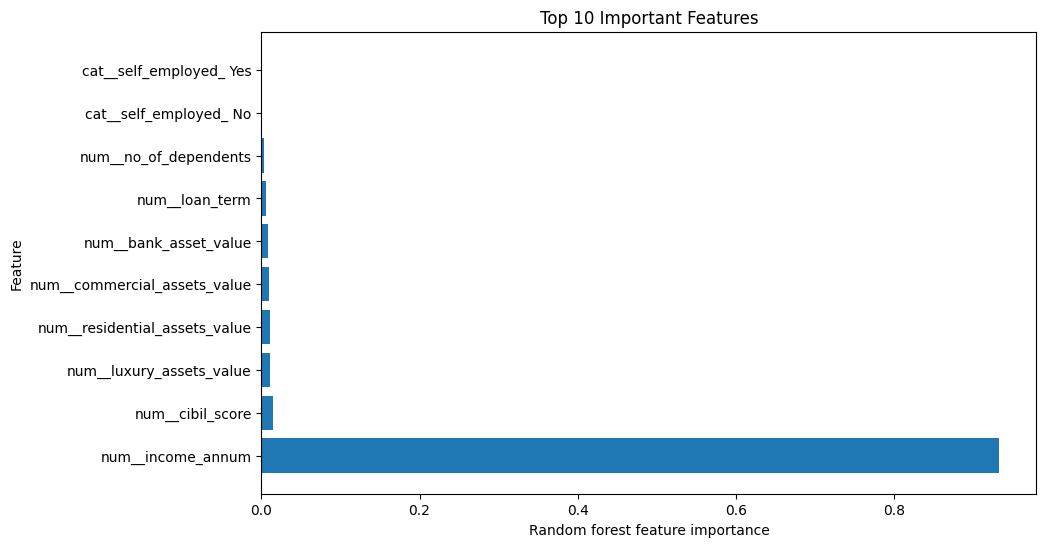

In [177]:
feature_importance = rf_reg_pipeline.named_steps['rf_reg'].feature_importances_

preprocessor = rf_reg_pipeline.named_steps['preprocessor']

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame(
    {
        'Feature' : feature_names,
        'Importance'  : feature_importance
    }
)

importance_df = importance_df.sort_values(by='Importance', ascending=False)

print("Top 10 Important Features : \n", importance_df.head(10))

plt.figure(figsize=(10,6))
plt.barh(importance_df['Feature'][:10], importance_df['Importance'][:10])
plt.xlabel("Random forest feature importance")
plt.ylabel("Feature")
plt.title("Top 10 Important Features")
plt.show()


# Save Artifacts and combine them in a prediction function

In [178]:
from pathlib import Path
import joblib

# Create models directory if it doesn't exist
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save models
joblib.dump(rf_clf_pipeline, models_dir / "stage_1_rf_classifier_pipeline.pkl")
joblib.dump(rf_reg_pipeline, models_dir / "stage_2_rf_regression_pipeline.pkl")


['..\\models\\stage_2_rf_regression_pipeline.pkl']

# Prediction Function

In [179]:
clf = joblib.load("../models/stage_1_rf_classifier_pipeline.pkl")
reg = joblib.load("../models/stage_2_rf_regression_pipeline.pkl")

In [180]:
def two_stage_predict(applicant_df):
    out = {}

    # stage 1
    approve = clf.predict(applicant_df)[0]
    # print(approve)
    out['loan_status'] = int(approve)

    if approve == 1:
        # stage 2
        applicant_df['loan_status'] = 'Approve'
        loan_amount_pred = reg.predict(applicant_df)[0]
        out['regression_prediction'] = float(loan_amount_pred)
    else:
        print("Not Approved")
    
    return out

In [181]:
example_row = X_test.iloc[[0]]
print("Example row : \n")
display(example_row)

Example row : 



,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
3933,0,Not Graduate,No,9800000,20100000,16,606,6200000,800000,37300000,8700000


In [182]:
example_row.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1 entries, 3933 to 3933
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   no_of_dependents          1 non-null      int64 
 1   education                 1 non-null      object
 2   self_employed             1 non-null      object
 3   income_annum              1 non-null      int64 
 4   loan_amount               1 non-null      int64 
 5   loan_term                 1 non-null      int64 
 6   cibil_score               1 non-null      int64 
 7   residential_assets_value  1 non-null      int64 
 8   commercial_assets_value   1 non-null      int64 
 9   luxury_assets_value       1 non-null      int64 
 10  bank_asset_value          1 non-null      int64 
dtypes: int64(9), object(2)
memory usage: 96.0+ bytes


In [183]:
print(reg.feature_names_in_)

['no_of_dependents' 'education' 'self_employed' 'income_annum' 'loan_term'
 'cibil_score' 'residential_assets_value' 'commercial_assets_value'
 'luxury_assets_value' 'bank_asset_value' 'loan_status']


In [184]:
print(clf.feature_names_in_)

['no_of_dependents' 'education' 'self_employed' 'income_annum'
 'loan_amount' 'loan_term' 'cibil_score' 'residential_assets_value'
 'commercial_assets_value' 'luxury_assets_value' 'bank_asset_value']


In [185]:
two_stage_predict(example_row)

C:\Users\lenovo\AppData\Local\Temp\ipykernel_29760\250454187.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  applicant_df['loan_status'] = 'Approve'


{'loan_status': 1, 'regression_prediction': 24705512.448567294}

In [186]:
sample = pd.DataFrame([{
    'no_of_dependents' : 1,
    'education' : 'Graduate',
    'self_employed' : 'No', 
    'income_annum' : 1200000,
    'loan_amount' : 30000,
    'loan_term' : 12, 
    'cibil_score' : 800, 
    'residential_assets_value' : 2000000,
    'commercial_assets_value' : 2000000, 
    'luxury_assets_value' : 0, 
    'bank_asset_value' : 55000
}])

In [187]:
sample

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,1,Graduate,No,1200000,30000,12,800,2000000,2000000,0,55000


In [188]:
two_stage_predict(sample)

{'loan_status': 1, 'regression_prediction': 3052769.1915370994}

In [189]:
approval_output = clf.predict(sample)
approval_output

array([1])

In [190]:
approval_proba = clf.predict_proba(sample)
approval_proba

array([[0.1875, 0.8125]])

In [191]:
approval_proba.shape

(1, 2)

In [192]:
approval_proba[0]

array([0.1875, 0.8125])

In [193]:
approval_proba[0][1]

np.float64(0.8125)

In [194]:
float(approval_proba[0, 1])

0.8125

In [203]:
import sys
sys.path.append(r"d:\Assessment\final\vehicle-loan-advisor\backend\services")
from policy_check import check_policy, check_ltv, verify_policy_text
print("Missing sections:", verify_policy_text())   # expect []

cases = {
    "clean":               ({"cibil_score": 720, "income_annum": 1_200_000, "self_employed": "No"},  20_000),
    "low score":           ({"cibil_score": 480, "income_annum": 1_200_000, "self_employed": "No"},  0),
    "heavy EMI (salaried)":({"cibil_score": 720, "income_annum": 600_000,   "self_employed": "No"},  27_000),
    "same EMI, self-emp":  ({"cibil_score": 720, "income_annum": 600_000,   "self_employed": "Yes"}, 24_000),
}

for name, (applicant, emi) in cases.items():
    print(name, "->", check_policy(applicant, emi))

print("LTV 90%:", check_ltv(1_000_000, 100_000))   # violation
print("LTV 80%:", check_ltv(1_000_000, 200_000))   # None

Missing sections: []
clean -> []
low score -> [{'rule': 'minimum_credit_score', 'section': '3.2', 'applicant_value': 480, 'policy_threshold': '>= 550'}]
heavy EMI (salaried) -> [{'rule': 'obligation_limit', 'section': '4.1', 'applicant_value': '54%', 'policy_threshold': '<= 50% of monthly income'}]
same EMI, self-emp -> [{'rule': 'obligation_limit_self_employed', 'section': '4.2', 'applicant_value': '48%', 'policy_threshold': '<= 45% of monthly income'}]
LTV 90%: {'rule': 'max_ltv', 'section': '7.1', 'applicant_value': '90%', 'policy_threshold': '<= 85% of vehicle price'}
LTV 80%: None


In [202]:
import os
os.getcwd()

'd:\\Assessment\\final\\vehicle-loan-advisor\\notebooks'